In [1]:
import strawberryfields as sf
from strawberryfields.ops import DisplacedSqueezed, MeasureHomodyne, LossChannel
import numpy as np
from matplotlib import pyplot as plt
import pymc as pm
import arviz as az

np.random.seed(42)

/home/amanuelant/.local/lib/python3.10/site-packages/strawberryfields/apps/data/sample.py:20: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
2025-07-25 08:58:21.538890: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2025-07-25 08:58:21.585388: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-07-25 08:58:21.585463: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-07-25 08:58:21.585517: E tensorflow/compiler/xla/stream_executor/cuda/cuda_bl

$$
\begin{align}
\mu = 2\sqrt{\frac{\hbar}{2}}\begin{bmatrix}\text{Re}(\alpha) \\ \text{Im}(\alpha) \end{bmatrix} \\
\Sigma = \frac{\hbar}{2}\begin{bmatrix} e^{-2z} & 0 \\ 0 & e^{2z} \end{bmatrix} \\
\end{align}
$$
Where $z=re^{i\phi}$ is the complex squeezing parameter but we have set the squeezing angle to $\phi=0$ so $z=r$


In [2]:
prog = sf.Program(1)
sf.hbar = 2 # Set reduced Planck's constant

alpha = 1.0  # Displacement amplitude
z = 1*0    # Squeezing parameter
eta = 0.0  # Loss percentage

with prog.context as q:
    DisplacedSqueezed(r_d=alpha, phi_d=0.0, r_s=z, phi_s=0.0) | q[0]
    LossChannel(T=1-eta) | q[0] 
    

# Use Gaussian formalism for exact calculations (up to numerical precision)
eng = sf.Engine("gaussian")
result = eng.run(prog)
state = result.state

# Get x quadrature mean and variance
mean_x, var_x = state.quad_expectation(mode=0, phi=0.0)
std_x = np.sqrt(var_x)

print(f"True E(x) = {mean_x:.4f},  True Var(x) = {var_x:.4f}, True Std(x) = {std_x:.4f}")


True E(x) = 2.0000,  True Var(x) = 1.0000, True Std(x) = 1.0000


In [3]:
lossless_mean_x = 2*np.sqrt(sf.hbar/2)*alpha
lossless_var_x = sf.hbar/2*np.exp(-2*z)
lossless_std_x = np.sqrt(lossless_var_x)

print("Analytic formula for (lossless) mean:", lossless_mean_x)
print("Analytic formula for (lossless) variance:", lossless_var_x)
print("Analytic formula for (lossless) standard deviation:", lossless_std_x)

Analytic formula for (lossless) mean: 2.0
Analytic formula for (lossless) variance: 1.0
Analytic formula for (lossless) standard deviation: 1.0


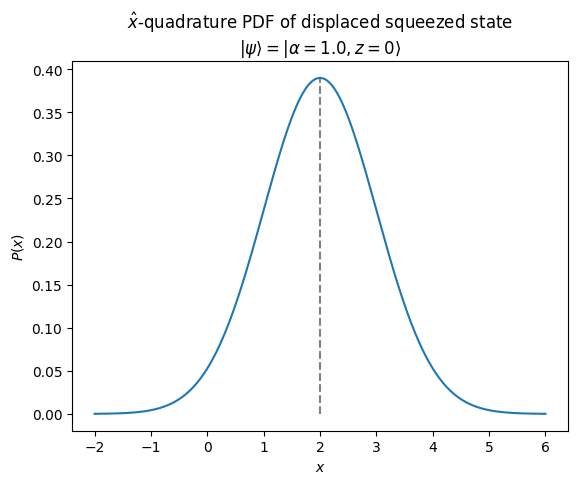

In [4]:
x_vals = np.linspace(mean_x-4*std_x, mean_x+4*std_x, 1000)

x_val_probs = state.x_quad_values(0, x_vals, x_vals)
plt.xlabel(r"$x$")
plt.ylabel(r"$P(x)$")
plt.title(r"$\hat{x}$-quadrature PDF of displaced squeezed state" + "\n" + fr"$|\psi\rangle = |\alpha={alpha},z={z}\rangle$")
plt.vlines(mean_x, 0, max(x_val_probs), colors='gray', linestyles='dashed')
plt.plot(x_vals, x_val_probs, label='x quadrature');

In [5]:
prog = sf.Program(1)
with prog.context as q:
    DisplacedSqueezed(r_d=1, phi_d=0.0, r_s=1.5, phi_s=0.0) | q[0]
    LossChannel(T=1-eta) | q[0] 
    MeasureHomodyne(phi=0.0) | q[0]
    

obsereved_data = [eng.run(prog).samples[0, 0] for _ in range(50)]  # make 10 measurements of x quadrature
print(obsereved_data)

[1.9691490519437136, 2.3398340322860562, 1.9477569623126874, 2.1712379028074165, 2.1210615580471726, 1.8960816037548707, 1.573089301106175, 1.874536643151051, 2.0701180858153707, 1.6848723223527442, 1.9496224776775404, 1.6820955813334686, 2.02475018514845, 2.083829592676144, 1.9349143007487224, 2.4132992939755815, 1.7639926962247172, 1.7275928514369647, 1.5627383157680095, 2.0439256967319084, 2.038237447386663, 1.9328146571928213, 1.8393809819766256, 2.235875946386532, 1.606612409757881, 1.9140764945840119, 2.136483483114906, 2.2077967655955857, 1.9310053653405739, 2.217673627888611, 1.9585738661626966, 1.733090117177769, 2.302618176339613, 2.223918546171293, 1.8560542680155332, 2.343182483249694, 2.349119329741899, 2.183391311097852, 1.93328241520384, 1.5565132516257856, 2.0796826172817764, 1.8843582367419307, 1.8880428255350088, 2.073354317214538, 2.1145254905556468, 2.216133998687871, 1.9268886633854712, 1.673445544063311, 2.0582493280884564, 1.9476565143343154]


$$
\begin{align}
x_i \sim \mathcal{N}\left(2\sqrt{\frac{\hbar}{2}}\alpha, \sigma \right) \\ 
\alpha \sim  \mathcal{N}(\mu_A, 1) \\
%\sigma \sim \text{Exp}\left(\lambda=\frac{1}{\sigma_A}\right)
\end{align}
$$

where $\mu_A$ and $\sigma_A$ are the analytical values of the quadrature mean and standard deviation computed for a lossless circuit.

In [6]:
with pm.Model() as m:
    #alpha = pm.Normal("alpha", mu=lossless_mean_x, sigma=1)
    alpha = pm.Normal("alpha", mu=1, sigma=np.sqrt(0.1))
    sigma = 1 #pm.Exponential("std_x", lam=1/lossless_std_x)

    pm.Normal("likelihood", mu=2*np.sqrt(sf.hbar/2)*alpha, sigma=sigma, observed=obsereved_data)

    trace = pm.sample(100_000, nuts_sampler='nutpie', progressbar=False)

/home/amanuelant/.local/lib/python3.10/site-packages/pytensor/link/c/cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library


In [7]:
print("Analytic formula for (lossless) mean:", lossless_mean_x)
print("Analytic formula for (lossless) standard deviation:", lossless_std_x)

var_names = ["alpha"] #, "std_x"]
summary = az.summary(trace, hdi_prob=0.95, var_names=var_names)

for var_name in var_names:
    print(f"Posterior mean of {var_name}:", summary['mean'][var_name])

Analytic formula for (lossless) mean: 2.0
Analytic formula for (lossless) standard deviation: 1.0
Posterior mean of alpha: 0.992


Below are some more verbose outputs from the MCMC sampling using `arviz`.

In [8]:
az.summary(trace, hdi_prob=0.95, var_names=var_names)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,0.992,0.069,0.857,1.127,0.0,0.0,171410.0,281834.0,1.0


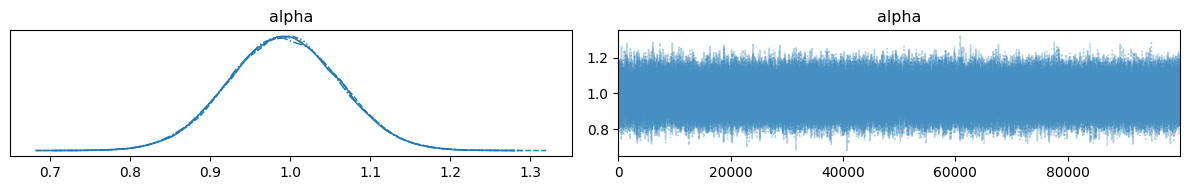

In [9]:
az.plot_trace(trace)
plt.tight_layout()
plt.show()

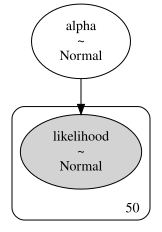

In [10]:
pm.model_to_graphviz(model=m)